# Hotel Booking Demand — What Factors Influence Cancellations?

**Goal:** To find out Why guests cancel hotel bookings and build a model that predicts cancellation.

**ML:** Linear Regression · Logistic Regression · Decision Tree · Random Forest


| # | Step | # | Step |
|---|------|---|------|
| 1 | Define the problem | 9 | Select ML algorithms |
| 2 | Collect data | 10 | Train models |
| 3 | Understand the data | 11 | Evaluate models |
| 4 | Clean the data | 12 | Tune / improve |
| 5 | EDA | 13 | Make predictions |
| 6 | Feature engineering | 14 | Visualize & report |
| 7 | Prepare data for ML | 15 | Deploy (Streamlit) |
| 8 | Split data | | |

## 1 Define the Problem

- **Business question:** What factors influence whether a hotel booking gets cancelled?
- **Target variable:** `is_canceled` (1 = cancelled, 0 = not cancelled)
- **Problem type:** Binary classification (+ interpretation of drivers)
- **Why it matters:** Cancellations cost revenue. If hotels can predict risky bookings, they can require deposits, overbook smartly, or contact guests early.
- **Success metrics:** Accuracy, Precision, Recall, F1 and ROC-AUC. Because the cost of missing a cancellation differs from a false alarm, we look at all of them rather than accuracy alone.

## 2 Collect Data

In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "joblib": "joblib>=1.3",
    "numpy": "numpy>=1.24",
    "pandas": "pandas>=2.0",
    "matplotlib": "matplotlib>=3.7",
    "seaborn": "seaborn>=0.12",
    "sklearn": "scikit-learn==1.8.0",
}
missing_packages = [
    package
    for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    print(f"Installing {', '.join(missing_packages)} into {sys.executable}")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", *missing_packages]
    )

import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)

In [2]:
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"

try:
    df = pd.read_csv(URL)
    print("Loaded dataset from URL")
except Exception as error:
    print(f"Dataset download failed: {error}")
    df = pd.read_csv("data/hotel_bookings.csv")

print(df.shape)
df.head()

Loaded dataset from URL
(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 3 Understand the Data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
display(df.describe().T)
print("\nTarget balance:")
print(df["is_canceled"].value_counts(normalize=True).rename({0:"Not canceled",1:"Canceled"}).round(3))

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0



Target balance:
is_canceled
Not canceled    0.63
Canceled        0.37
Name: proportion, dtype: float64


In [5]:
miss = df.isna().sum()
print(miss[miss > 0])
print("Duplicate rows:", df.duplicated().sum())

children         4
country        488
agent        16340
company     112593
dtype: int64
Duplicate rows: 31994


**Data dictionary highlights**

- `lead_time` – days between booking and arrival
- `deposit_type` – No Deposit / Non Refund / Refundable
- `previous_cancellations` – earlier cancelled bookings by the same guest
- `market_segment`, `distribution_channel` – how the booking was made
- `adr` – average daily rate (price per night)
- `total_of_special_requests`, `required_car_parking_spaces`, `booking_changes` – guest engagement
- `reservation_status` and `reservation_status_date` **reveal the outcome** (data leakage!) → we must drop them before modelling.

## 4 Clean the Data

In [6]:
data = df.copy()

data["children"] = data["children"].fillna(0)
data["country"] = data["country"].fillna("Unknown")
data = data.drop(columns=["agent", "company"], errors="ignore")

data = data.drop(columns=["reservation_status", "reservation_status_date"], errors="ignore")

data = data[(data["adults"] + data["children"] + data["babies"]) > 0]
data = data[(data["stays_in_weekend_nights"] + data["stays_in_week_nights"]) > 0]

data = data[(data["adr"] >= 0) & (data["adr"] < 1000)]

data = data.drop_duplicates()

data = data.drop(columns=["assigned_room_type"], errors="ignore")

data = data.reset_index(drop=True)
os.makedirs("cleaning", exist_ok=True)
data.to_csv("cleaning/cleaned_hotel_bookings.csv", index=False)
print("Rows before:", len(df), "| after cleaning:", len(data), "| saved to cleaning/cleaned_hotel_bookings.csv")

Rows before: 119390 | after cleaning: 86351 | saved to cleaning/cleaned_hotel_bookings.csv


## 5 Exploratory Data Analysis (EDA)

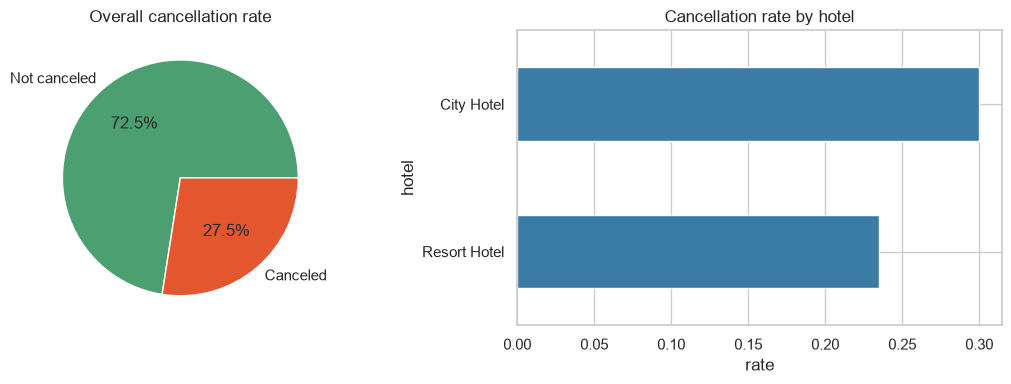

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
data["is_canceled"].value_counts().plot.pie(autopct="%1.1f%%", labels=["Not canceled","Canceled"],
    colors=["#4C9F70","#E4572E"], ax=axes[0], ylabel="")
axes[0].set_title("Overall cancellation rate")
rate = data.groupby("hotel")["is_canceled"].mean().sort_values()
rate.plot.barh(color="#3A7CA5", ax=axes[1])
axes[1].set_title("Cancellation rate by hotel")
axes[1].set_xlabel("rate")
plt.tight_layout()
plt.savefig("outputs/eda_overview.png", dpi=120)
plt.show()

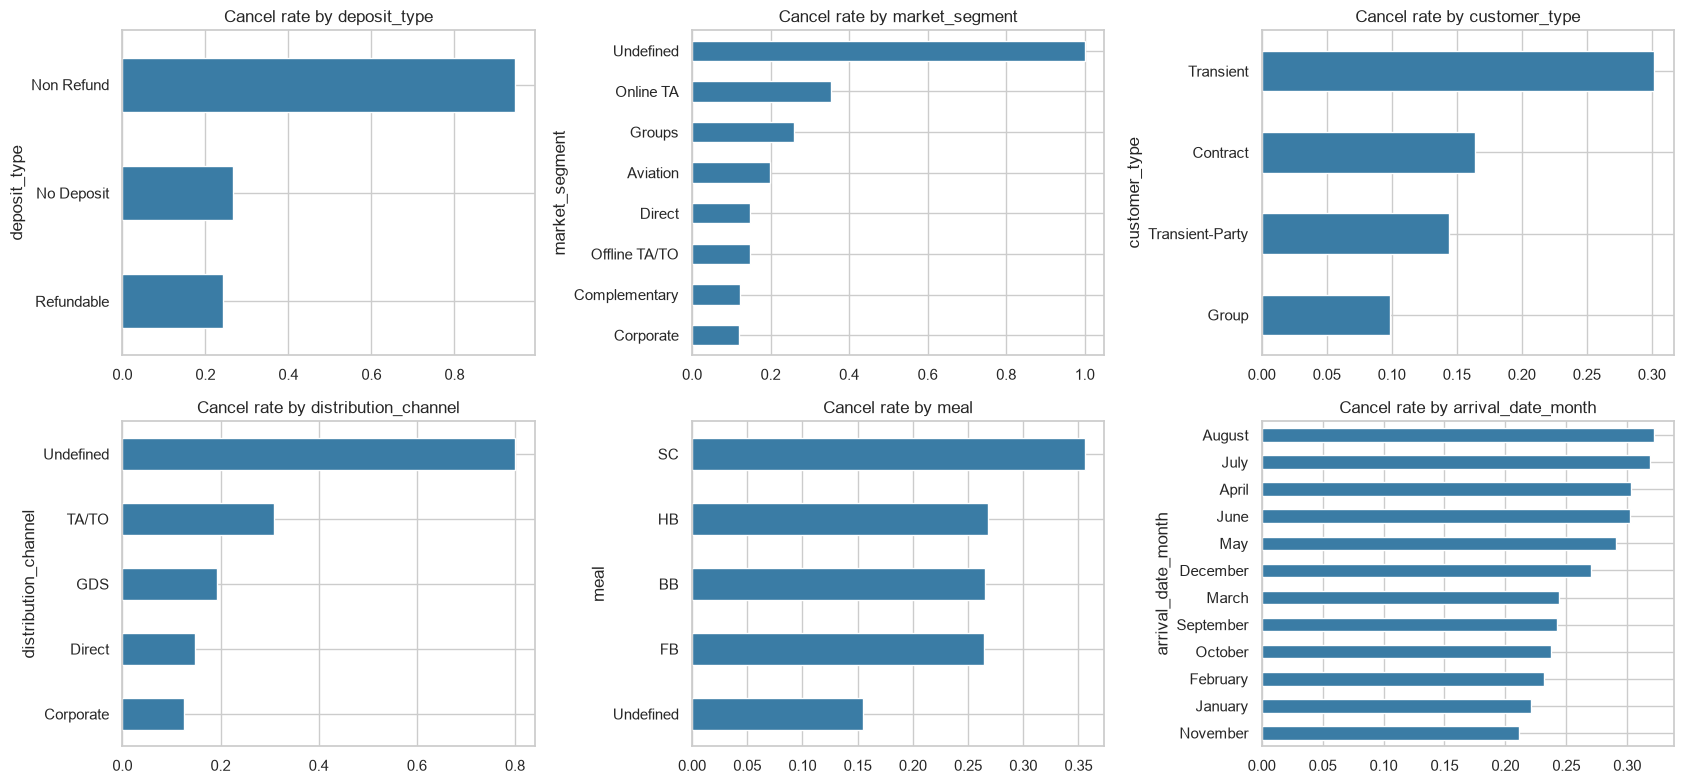

In [8]:
cat_cols = ["deposit_type", "market_segment", "customer_type", "distribution_channel", "meal", "arrival_date_month"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    r = data.groupby(c)["is_canceled"].mean().sort_values()
    r.plot.barh(ax=ax, color="#3A7CA5")
    ax.set_title(f"Cancel rate by {c}")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("outputs/eda_categorical.png", dpi=120)
plt.show()

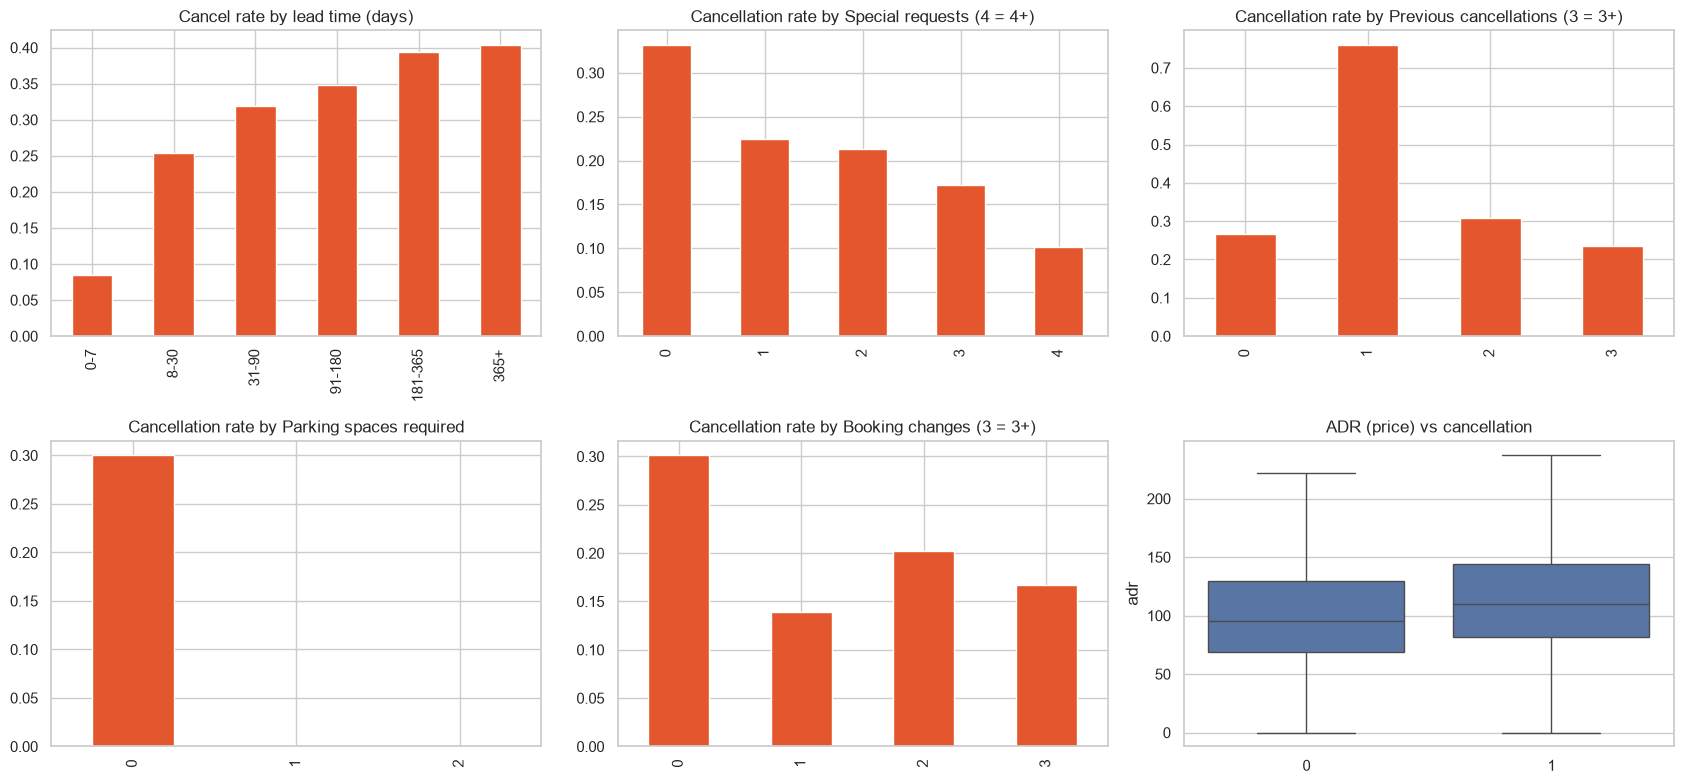

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))

lead_time_bins = pd.cut(
    data["lead_time"],
    [-1, 7, 30, 90, 180, 365, 1000],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"],
)
data.groupby(lead_time_bins, observed=True)["is_canceled"].mean().plot.bar(
    ax=axes[0, 0], color="#E4572E"
)
axes[0, 0].set_title("Cancel rate by lead time (days)")

numeric_charts = [
    ("total_of_special_requests", 4, axes[0, 1], "Special requests (4 = 4+)"),
    ("previous_cancellations", 3, axes[0, 2], "Previous cancellations (3 = 3+)"),
    ("required_car_parking_spaces", 2, axes[1, 0], "Parking spaces required"),
    ("booking_changes", 3, axes[1, 1], "Booking changes (3 = 3+)"),
]
for column, upper_limit, axis, title in numeric_charts:
    values = data[column].clip(upper=upper_limit)
    cancellation_rate = data.groupby(values)["is_canceled"].mean()
    cancellation_rate.plot.bar(ax=axis, color="#E4572E")
    axis.set_title(f"Cancellation rate by {title}")

sns.boxplot(data=data, x="is_canceled", y="adr", ax=axes[1, 2], showfliers=False)
axes[1, 2].set_title("ADR (price) vs cancellation")
for axis in axes.ravel():
    axis.set_xlabel("")

plt.tight_layout()
plt.savefig("outputs/eda_numeric.png", dpi=120)
plt.show()

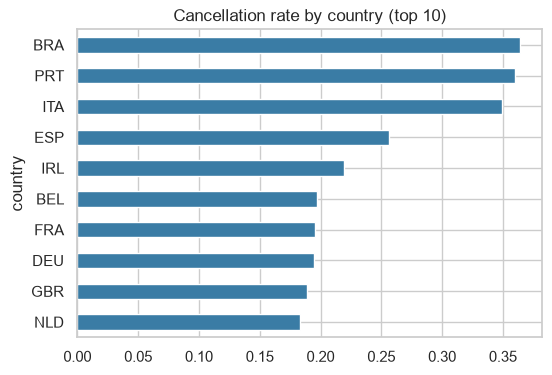

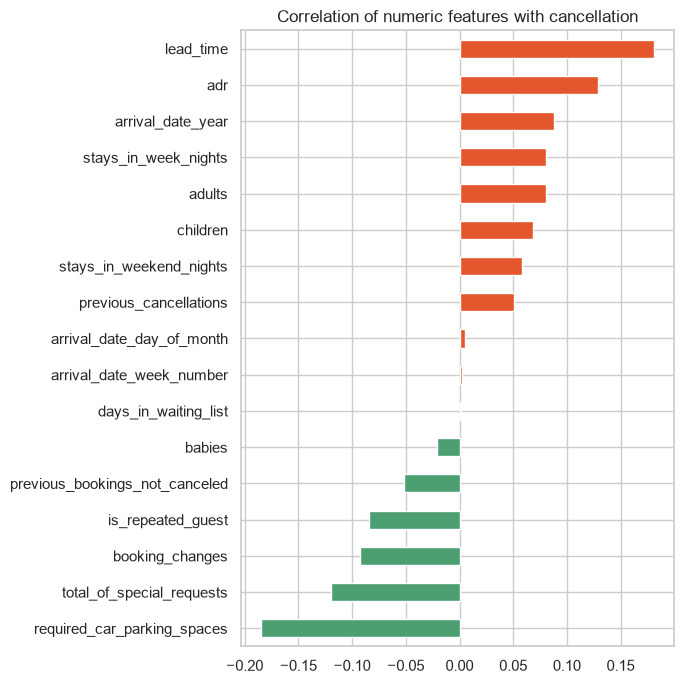

In [10]:
top_countries = data["country"].value_counts().head(10).index
country_cancellation_rate = (
    data[data["country"].isin(top_countries)]
    .groupby("country")["is_canceled"]
    .mean()
    .sort_values()
)
country_cancellation_rate.plot.barh(figsize=(6, 4), color="#3A7CA5")
plt.title("Cancellation rate by country (top 10)")
plt.show()

numeric_data = data.select_dtypes(include=[np.number])
correlation = (
    numeric_data.corr()["is_canceled"]
    .drop("is_canceled")
    .sort_values()
)
correlation.plot.barh(
    figsize=(7, 7),
    color=np.where(correlation > 0, "#E4572E", "#4C9F70"),
)
plt.title("Correlation of numeric features with cancellation")
plt.tight_layout()
plt.savefig("outputs/eda_correlation.png", dpi=120)
plt.show()

**EDA takeaways** (numbers from the cleaned dataset, ~86k bookings, ~28% cancelled)
- **Lead time:** bookings made ≤7 days ahead cancel ~8% of the time; 6+ months ahead ~40%.
- **Online TA** (travel-agency websites) bookings cancel ~35% vs ~12–15% for Direct / Corporate / Offline TA.
- **Hotel:** City Hotel (~30%) cancels more than Resort Hotel (~24%).
- **Previous cancellations:** guests with exactly one earlier cancellation cancel again ~76% of the time.
- **"Non Refund" deposits** have a ~95% cancellation rate — counter-intuitive! It's a known quirk of this dataset (a small group of bookings flagged non-refundable that were still recorded as cancelled), so treat it as a data pattern, not as advice to remove non-refundable rates.
- **Special requests:** 0 requests → ~33% cancel; 3+ requests → ~16%.
- **Parking:** guests who required a parking space essentially never cancelled (0%).
- **Repeat guests** cancel far less (~8% vs ~28%).

## 6 Feature Engineering

In [11]:
def add_features(d):
    d = d.copy()
    d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
    d["total_guests"] = d["adults"] + d["children"] + d["babies"]
    d["is_family"] = ((d["children"] + d["babies"]) > 0).astype(int)
    d["has_special_req"] = (d["total_of_special_requests"] > 0).astype(int)
    d["has_prev_cancel"] = (d["previous_cancellations"] > 0).astype(int)
    d["weekend_share"] = d["stays_in_weekend_nights"] / d["total_nights"]
    return d

data = add_features(data)
data[["total_nights","total_guests","is_family","has_special_req","has_prev_cancel","weekend_share"]].describe().T

,count,mean,std,min,25%,50%,75%,max
total_nights,86351.0,3.653658,2.733292,1.0,2.0,3.00,5.0,69.0
total_guests,86351.0,2.031094,0.791190,1.0,2.0,2.00,2.0,55.0
is_family,86351.0,0.104816,0.306318,0.0,0.0,0.00,0.0,1.0
has_special_req,86351.0,0.499728,0.500003,0.0,0.0,0.00,1.0,1.0
has_prev_cancel,86351.0,0.019143,0.137028,0.0,0.0,0.00,0.0,1.0
weekend_share,86351.0,0.265034,0.280115,0.0,0.0,0.25,0.4,1.0


## 7 Prepare Data for ML

We build one scikit-learn **Pipeline** so the *exact same* preprocessing is used in training and in the Streamlit app:
- Numeric → impute median + scale
- Categorical → impute + One-Hot Encode (rare categories grouped automatically)

In [12]:
TARGET = "is_canceled"

NUM_FEATURES = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "booking_changes", "days_in_waiting_list", "adr", "required_car_parking_spaces",
    "total_of_special_requests", "total_nights", "total_guests", "is_family",
    "has_special_req", "has_prev_cancel", "weekend_share"]

CAT_FEATURES = ["hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "deposit_type", "customer_type"]

X = data[NUM_FEATURES + CAT_FEATURES]
y = data[TARGET]

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200))])

preprocessor = ColumnTransformer([("num", numeric_pipe, NUM_FEATURES),
    ("cat", categorical_pipe, CAT_FEATURES)])
print(X.shape)

(86351, 29)


## 8 Split Data
Stratified 80/20 split keeps the cancel/not-cancel ratio the same in train and test.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train cancel rate:", round(y_train.mean(),3), "| Test cancel rate:", round(y_test.mean(),3))

Train: (69080, 29) | Test: (17271, 29)
Train cancel rate: 0.275 | Test cancel rate: 0.275


## 9 Select ML Algorithms

| Model | Why |
|---|---|
| **Linear Regression** | Simple baseline. Predicts a score (0–1) that we threshold at 0.5 — not ideal for classification, but a classic starting point |
| **Logistic Regression** | The proper linear model for yes/no outcomes; coefficients are easy to interpret |
| **Decision Tree** | Human-readable rules, captures non-linear effects |
| **Random Forest** | Many trees averaged → usually the most accurate, gives feature importance |

In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=30, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=18, min_samples_leaf=3,
    n_jobs=-1, random_state=RANDOM_STATE),
}

## Train Models

In [15]:
fitted = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    print("trained:", name)

trained: Linear Regression
trained: Logistic Regression
trained: Decision Tree
trained: Random Forest


## 11 Evaluate Models

In [16]:
def get_scores(name, pipe, features):
    """Return cancellation scores for classifiers and clipped predictions for regression."""
    if name == "Linear Regression":
        return np.clip(pipe.predict(features), 0, 1)
    return pipe.predict_proba(features)[:, 1]


rows, scores = [], {}
for name, pipe in fitted.items():
    score = get_scores(name, pipe, X_test)
    scores[name] = score
    prediction = (score >= 0.5).astype(int)
    rows.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, prediction),
            "Precision": precision_score(y_test, prediction),
            "Recall": recall_score(y_test, prediction),
            "F1": f1_score(y_test, prediction),
            "ROC-AUC": roc_auc_score(y_test, score),
        }
    )

results = (
    pd.DataFrame(rows)
    .set_index("Model")
    .round(4)
    .sort_values("ROC-AUC", ascending=False)
)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.8172,0.7413,0.5139,0.6070,0.8815
Decision Tree,0.8043,0.6624,0.5864,0.6221,0.8543
Logistic Regression,0.7973,0.6894,0.4772,0.5640,0.8386
Linear Regression,0.7924,0.7249,0.3933,0.5100,0.8307


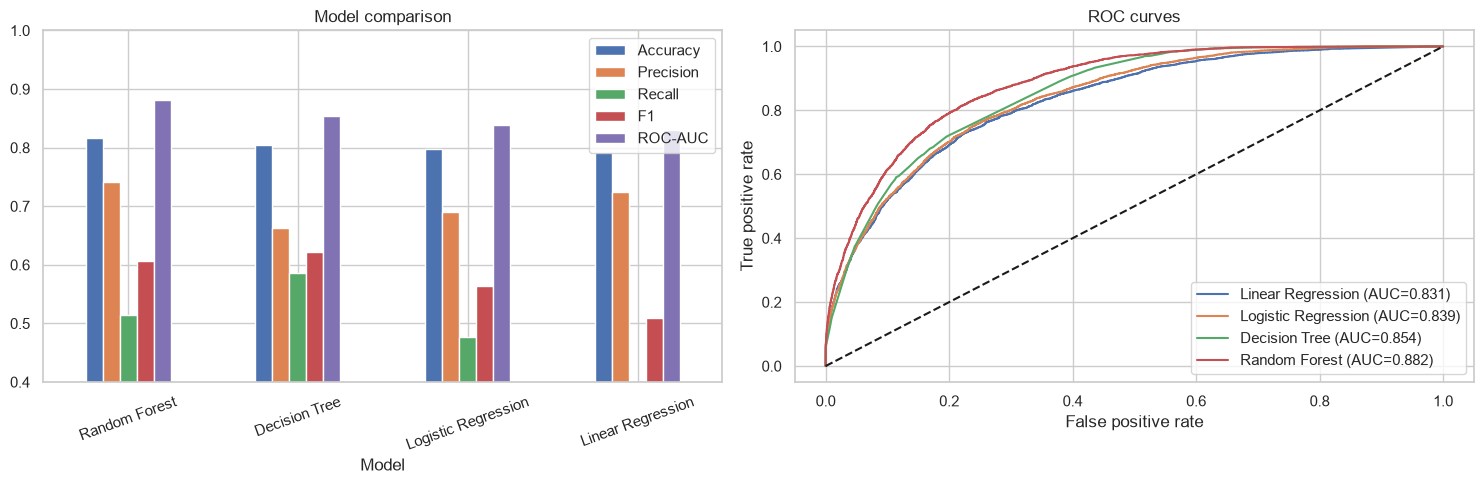

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
results.plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Model comparison")
axes[0].set_ylim(0.4, 1)

for name, score in scores.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, score)
    auc = roc_auc_score(y_test, score)
    axes[1].plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{name} (AUC={auc:.3f})",
    )

axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC curves")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend()
plt.tight_layout()
plt.savefig("outputs/model_comparison.png", dpi=120)
plt.show()

Best model so far: Random Forest
              precision    recall  f1-score   support

Not canceled       0.84      0.93      0.88     12527
    Canceled       0.74      0.51      0.61      4744

    accuracy                           0.82     17271
   macro avg       0.79      0.72      0.74     17271
weighted avg       0.81      0.82      0.81     17271



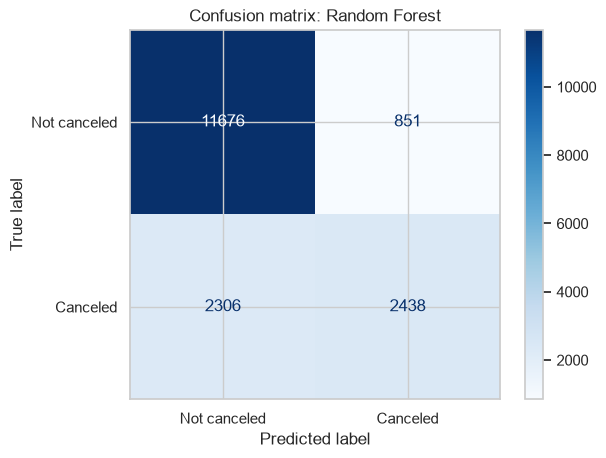

In [18]:
best_name = results.index[0]
print("Best model so far:", best_name)
predictions = (scores[best_name] >= 0.5).astype(int)
print(
    classification_report(
        y_test,
        predictions,
        target_names=["Not canceled", "Canceled"],
    )
)

confusion_matrix_display = ConfusionMatrixDisplay(
    confusion_matrix(y_test, predictions),
    display_labels=["Not canceled", "Canceled"],
)
confusion_matrix_display.plot(cmap="Blues")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

## 12 Tune / Improve the Model
We tune the Random Forest with `RandomizedSearchCV` (on a 30k sample to keep runtime manageable), optimizing ROC-AUC, then refit on the full training set.

In [19]:
rf_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))])

param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [12, 18, 25, None],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", 0.3, 0.5],
    "model__class_weight": [None, "balanced"],
}
sample_idx = X_train.sample(30000, random_state=RANDOM_STATE).index
search = RandomizedSearchCV(rf_pipe, param_dist, n_iter=8, scoring="roc_auc",
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1, verbose=1)
search.fit(X_train.loc[sample_idx], y_train.loc[sample_idx])
print("Best params:", search.best_params_)
print("Best CV AUC:", round(search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best params: {'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}
Best CV AUC: 0.8758


In [20]:
best_rf = Pipeline([("prep", preprocessor),
    ("model", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE,
    **{k.replace("model__",""): v for k, v in search.best_params_.items()}))])
best_rf.fit(X_train, y_train)

s = best_rf.predict_proba(X_test)[:, 1]
pred = (s >= 0.5).astype(int)
tuned = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, s)}
results.loc["Random Forest (tuned)"] = pd.Series(tuned).round(4)
results.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest (tuned),0.8250,0.6705,0.7133,0.6912,0.8900
Random Forest,0.8172,0.7413,0.5139,0.6070,0.8815
Decision Tree,0.8043,0.6624,0.5864,0.6221,0.8543
Logistic Regression,0.7973,0.6894,0.4772,0.5640,0.8386
Linear Regression,0.7924,0.7249,0.3933,0.5100,0.8307


## 13 Make Predictions — and answer the question: *What drives cancellations?*

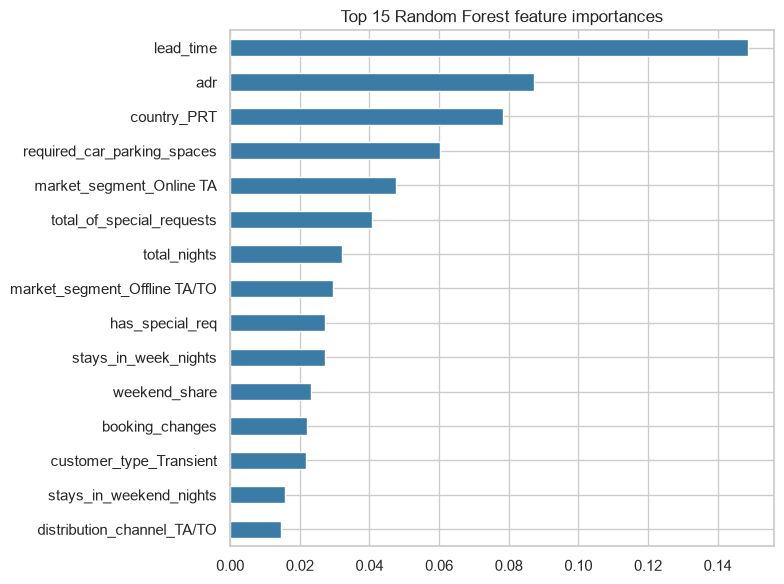

In [21]:
feature_names = best_rf.named_steps["prep"].get_feature_names_out()
feature_names = [
    name.replace("num__", "").replace("cat__", "")
    for name in feature_names
]
importance = pd.Series(
    best_rf.named_steps["model"].feature_importances_,
    index=feature_names,
).sort_values(ascending=False)

importance.head(15).sort_values().plot.barh(figsize=(8, 6), color="#3A7CA5")
plt.title("Top 15 Random Forest feature importances")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=120)
plt.show()

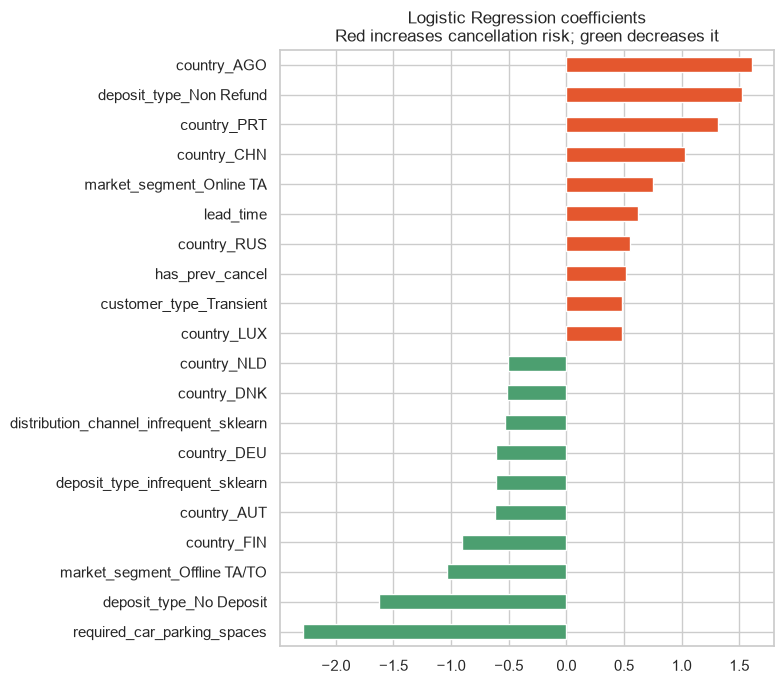

In [22]:
logistic_model = fitted["Logistic Regression"]
logistic_feature_names = logistic_model.named_steps["prep"].get_feature_names_out()
logistic_feature_names = [
    name.replace("num__", "").replace("cat__", "")
    for name in logistic_feature_names
]
coefficients = pd.Series(
    logistic_model.named_steps["model"].coef_[0],
    index=logistic_feature_names,
).sort_values()
top_coefficients = pd.concat(
    [coefficients.head(10), coefficients.tail(10)]
)

colors = np.where(top_coefficients > 0, "#E4572E", "#4C9F70")
top_coefficients.plot.barh(figsize=(8, 7), color=colors)
plt.title(
    "Logistic Regression coefficients\n"
    "Red increases cancellation risk; green decreases it"
)
plt.tight_layout()
plt.savefig("outputs/logistic_coefficients.png", dpi=120)
plt.show()

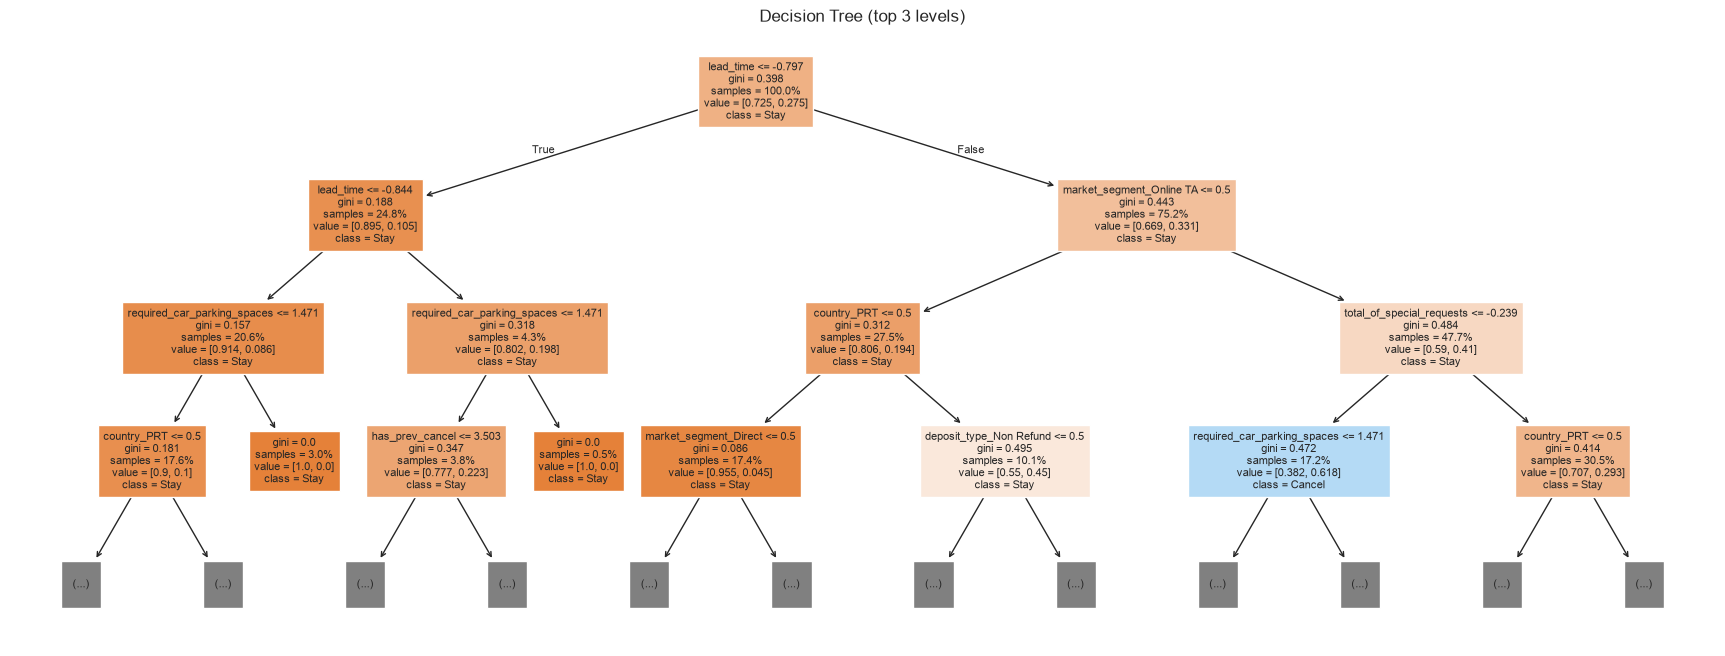

In [23]:
tree_pipe = fitted["Decision Tree"]
tree_feature_names = tree_pipe.named_steps["prep"].get_feature_names_out()
tree_feature_names = [
    name.replace("num__", "").replace("cat__", "")
    for name in tree_feature_names
]

plt.figure(figsize=(22, 8))
plot_tree(
    tree_pipe.named_steps["model"],
    feature_names=tree_feature_names,
    class_names=["Stay", "Cancel"],
    max_depth=3,
    filled=True,
    fontsize=8,
    proportion=True,
)
plt.title("Decision Tree (top 3 levels)")
plt.savefig("outputs/decision_tree.png", dpi=110)
plt.show()

In [24]:
new_booking = pd.DataFrame([{
    "hotel": "City Hotel", "arrival_date_month": "August", "meal": "BB", "country": "PRT",
    "market_segment": "Online TA", "distribution_channel": "TA/TO", "reserved_room_type": "A",
    "deposit_type": "No Deposit", "customer_type": "Transient",
    "lead_time": 150, "stays_in_weekend_nights": 1, "stays_in_week_nights": 3, "adults": 2, "children": 0, "babies": 0,
    "is_repeated_guest": 0, "previous_cancellations": 0, "previous_bookings_not_canceled": 0,
    "booking_changes": 0, "days_in_waiting_list": 0, "adr": 110.0, "required_car_parking_spaces": 0,
    "total_of_special_requests": 0}])
new_booking = add_features(new_booking)[NUM_FEATURES + CAT_FEATURES]
p = best_rf.predict_proba(new_booking)[0, 1]
print(f"Probability of cancellation: {p:.1%} ->", "HIGH RISK" if p >= 0.5 else "lower risk")

Probability of cancellation: 80.4% -> HIGH RISK


## 14 Visualize & Report Results

In [25]:
final = results.sort_values("ROC-AUC", ascending=False)
display(final)

print("\nTop 8 drivers of cancellation (Random Forest):")
display(importance.head(8).round(4).to_frame("importance"))
final.to_csv("outputs/model_results.csv")
importance.to_csv("outputs/feature_importance.csv")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest (tuned),0.8250,0.6705,0.7133,0.6912,0.8900
Random Forest,0.8172,0.7413,0.5139,0.6070,0.8815
Decision Tree,0.8043,0.6624,0.5864,0.6221,0.8543
Logistic Regression,0.7973,0.6894,0.4772,0.5640,0.8386
Linear Regression,0.7924,0.7249,0.3933,0.5100,0.8307



Top 8 drivers of cancellation (Random Forest):


,importance
lead_time,0.1487
adr,0.0872
country_PRT,0.0783
required_car_parking_spaces,0.0602
market_segment_Online TA,0.0477
total_of_special_requests,0.0408
total_nights,0.0321
market_segment_Offline TA/TO,0.0294


### Summary of Findings

1. **Most influential factors** (Random Forest importance): lead time, ADR (price), country (Portugal), required parking spaces, market segment (Online TA / Offline TA/TO), special requests, length of stay, and deposit type.
2. **Higher risk:** long lead times, Online TA bookings, City Hotel, no special requests, guests with a prior cancellation, bookings from Portugal, and the "Non Refund" deposit group.
3. **Lower risk:** short lead time, special requests, parking required, booking changes, repeat guests, and Direct / Corporate bookings.
4. **Best model:** the tuned Random Forest (AUC ≈ 0.89, accuracy ≈ 82%, recall ≈ 71% when `class_weight="balanced"`), followed by Decision Tree, Logistic Regression and Linear Regression (weakest, as expected for a yes/no target). Your numbers may vary slightly between runs.
5. **Business actions:** flag high-risk bookings for a reminder or deposit, offer flexible incentives for long-lead bookings, review Online TA policies, and use predicted probabilities to guide overbooking.

 *Caveats:* data covers two Portuguese hotels (2015–2017); correlation ≠ causation; the 0.5 threshold can be moved to favour recall or precision; some dataset quirks (e.g. Non Refund) may not generalise.

## 15 Deploy Model (Streamlit)

We save the whole pipeline (preprocessing + model) and the list of options the UI needs, then run the Streamlit app.

In [26]:
model_bundle = {
    "model": best_rf,
    "num_features": NUM_FEATURES,
    "cat_features": CAT_FEATURES,
    "countries": data["country"].value_counts().head(30).index.tolist(),
    "room_types": sorted(data["reserved_room_type"].unique().tolist()),
    "market_segments": sorted(data["market_segment"].unique().tolist()),
    "distribution_channels": sorted(data["distribution_channel"].unique().tolist()),
    "meals": sorted(data["meal"].unique().tolist()),
    "deposit_types": sorted(data["deposit_type"].unique().tolist()),
    "customer_types": sorted(data["customer_type"].unique().tolist()),
    "importance": importance.head(15).to_dict(),
}
os.makedirs("training", exist_ok=True)
joblib.dump(model_bundle, "training/model.joblib", compress=3)
print("Saved training/model.joblib (", round(os.path.getsize("training/model.joblib")/1e6, 1), "MB )")

Saved training/model.joblib ( 59.7 MB )


In [27]:
from asyncio import Handle


joblib.dump(Handle, "model.joblib", compress=3)


['model.joblib']